# validation_predictions

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
vali_pre = pd.read_csv("validation_predictions.csv")

In [4]:
vali_pre.head

<bound method NDFrame.head of          load_id  predicted_rate
0      TE-000001          828.38
1      TE-000002         5054.89
2      TE-000003         5167.78
3      TE-000004         4140.13
4      TE-000005         1836.93
...          ...             ...
11995  TE-011996          880.38
11996  TE-011997         1727.58
11997  TE-011998          898.70
11998  TE-011999         3411.39
11999  TE-012000          565.46

[12000 rows x 2 columns]>

In [5]:
vali_pre.shape

(12000, 2)

In [6]:
print(vali_pre.columns.tolist())


['load_id', 'predicted_rate']


In [7]:
vali_pre.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   load_id         12000 non-null  object 
 1   predicted_rate  12000 non-null  float64
dtypes: float64(1), object(1)
memory usage: 187.6+ KB


In [8]:
# Dataset dimensions
print("Dataset shape:", vali_pre.shape)
print("Rows:", vali_pre.shape[0])
print("Columns:", vali_pre.shape[1])
print("Column names:", vali_pre.columns.tolist())


Dataset shape: (12000, 2)
Rows: 12000
Columns: 2
Column names: ['load_id', 'predicted_rate']


In [9]:
# Random 5 rows
display(vali_pre.sample(5, random_state=42))

,load_id,predicted_rate
1935,TE-001936,4680.12
6494,TE-006495,2388.94
1720,TE-001721,5512.84
9120,TE-009121,3788.73
360,TE-000361,3537.56


In [10]:
# Missing values
print("Missing values:")
print(vali_pre.isnull().sum())

Missing values:
load_id           0
predicted_rate    0
dtype: int64


In [11]:
# Missing value percentages
print("\nMissing value percentage:")
print((vali_pre.isnull().mean() * 100).round(2))


Missing value percentage:
load_id           0.0
predicted_rate    0.0
dtype: float64


In [12]:
# Duplicate rows
print("\nDuplicate rows:", vali_pre.duplicated().sum())


Duplicate rows: 0


In [13]:
# Duplicate shipment IDs
print("Duplicate load IDs:", vali_pre["load_id"].duplicated().sum())

Duplicate load IDs: 0


In [14]:
# Data types
print("\nData types:")
print(vali_pre.dtypes)


Data types:
load_id            object
predicted_rate    float64
dtype: object


In [15]:
# Unique values
print("\nUnique values:")
print(vali_pre.nunique())


Unique values:
load_id           12000
predicted_rate    11818
dtype: int64


In [16]:
df = vali_pre.copy()

# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

In [17]:
# Remove duplicate rows
df = df.drop_duplicates()

In [18]:
# Convert predicted_rate to numeric
df["predicted_rate"] = pd.to_numeric(
    df["predicted_rate"], errors="coerce"
)


In [19]:
# Inspect missing rows before deciding how to handle them
display(df[df["predicted_rate"].isna()])

# Remove rows with missing IDs or missing predictions, if appropriate
df = df.dropna(subset=["load_id", "predicted_rate"])

print("Cleaned shape:", df.shape)

,load_id,predicted_rate


Cleaned shape: (12000, 2)


In [20]:
df

,load_id,predicted_rate
0,TE-000001,828.38
1,TE-000002,5054.89
2,TE-000003,5167.78
3,TE-000004,4140.13
4,TE-000005,1836.93
...,...,...
11995,TE-011996,880.38
11996,TE-011997,1727.58
11997,TE-011998,898.70
11998,TE-011999,3411.39


In [21]:
print("Summary statistics:")
display(df.describe(include="all").T)

print("Median rate:", df["predicted_rate"].median())


Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
load_id,12000,12000,TE-000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
predicted_rate,12000.0,NaN,NaN,NaN,2404.268098,1407.185186,156.46,1286.545,2060.985,3426.5375,9274.33


Median rate: 2060.985


In [22]:
print("Mean rate:", df["predicted_rate"].mean())


Mean rate: 2404.2680975000003


In [23]:
print("Minimum rate:", df["predicted_rate"].min())


Minimum rate: 156.46


In [24]:
print("Maximum rate:", df["predicted_rate"].max())


Maximum rate: 9274.33


In [25]:
print("Standard deviation:", df["predicted_rate"].std())

Standard deviation: 1407.1851858277637


In [26]:
print("Total predicted rate:", df["predicted_rate"].sum())

Total predicted rate: 28851217.17


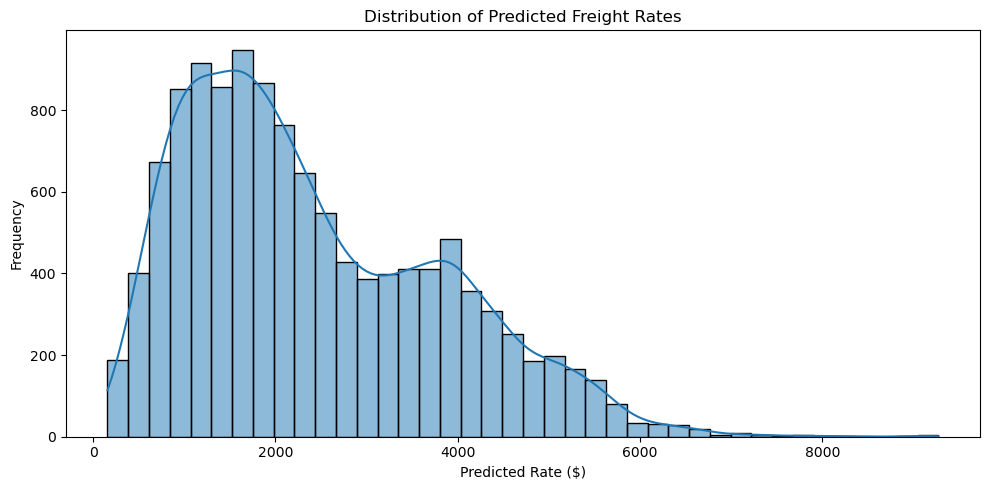

In [27]:
plt.figure(figsize=(10, 5))
sns.histplot(df["predicted_rate"], bins=40, kde=True)
plt.title("Distribution of Predicted Freight Rates")
plt.xlabel("Predicted Rate ($)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

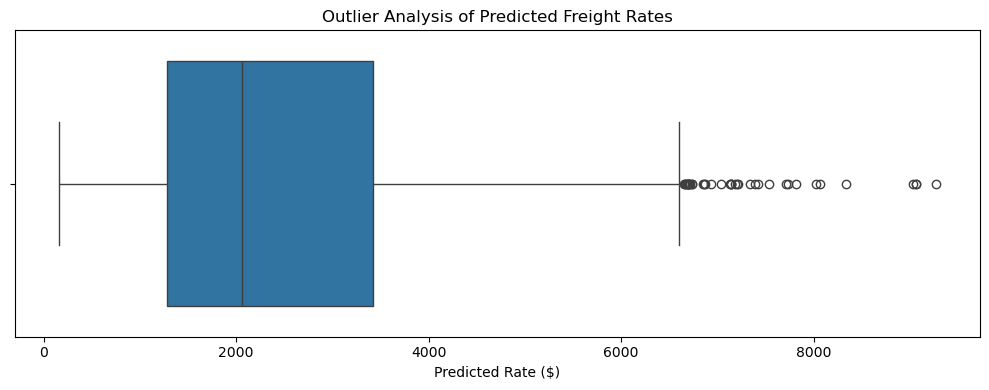

In [28]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["predicted_rate"])
plt.title("Outlier Analysis of Predicted Freight Rates")
plt.xlabel("Predicted Rate ($)")
plt.tight_layout()
plt.show()


In [29]:
# IQR method: flag potential outliers
Q1 = df["predicted_rate"].quantile(0.25)
Q3 = df["predicted_rate"].quantile(0.75)
IQR = Q3 - Q1


In [30]:
IQR

2139.9925

In [31]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [32]:
lower_bound

-1923.4437499999995

In [33]:
upper_bound

6636.526249999999

In [34]:
outliers = df[
    (df["predicted_rate"] < lower_bound) |
    (df["predicted_rate"] > upper_bound)
]
outliers

,load_id,predicted_rate
503,TE-000504,7395.95
519,TE-000520,8064.51
936,TE-000937,6652.24
1168,TE-001169,7181.29
1953,TE-001954,6717.73
2197,TE-002198,7534.71
3143,TE-003144,9274.33
3227,TE-003228,7216.21
3244,TE-003245,7127.66
3466,TE-003467,7201.47


In [35]:
print("Potential outliers:", len(outliers))
display(outliers.head(10))

Potential outliers: 39


,load_id,predicted_rate
503,TE-000504,7395.95
519,TE-000520,8064.51
936,TE-000937,6652.24
1168,TE-001169,7181.29
1953,TE-001954,6717.73
2197,TE-002198,7534.71
3143,TE-003144,9274.33
3227,TE-003228,7216.21
3244,TE-003245,7127.66
3466,TE-003467,7201.47


In [36]:
top_10 = df.nlargest(10, "predicted_rate")

display(top_10)

,load_id,predicted_rate
3143,TE-003144,9274.33
10037,TE-010038,9070.05
5908,TE-005909,9062.99
6223,TE-006224,9031.75
4744,TE-004745,8336.23
519,TE-000520,8064.51
6455,TE-006456,8023.75
8961,TE-008962,7814.75
3893,TE-003894,7730.81
11104,TE-011105,7709.12


<Axes: xlabel='predicted_rate', ylabel='load_id'>

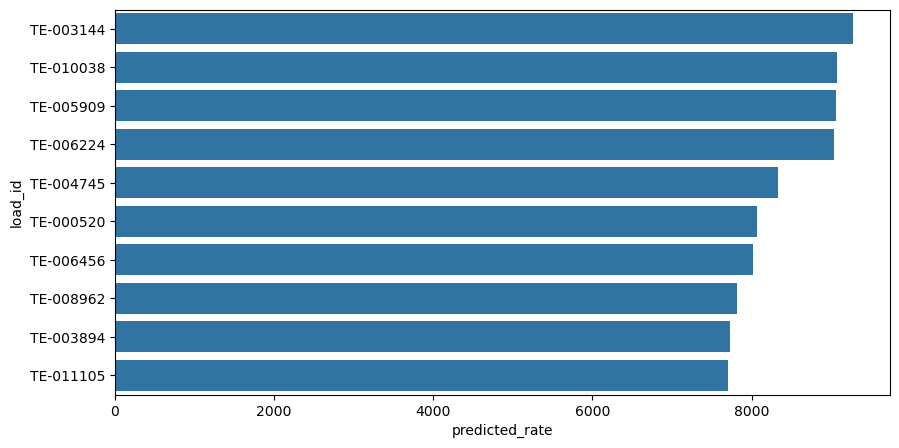

In [37]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_10,
    x="predicted_rate",
    y="load_id"
)

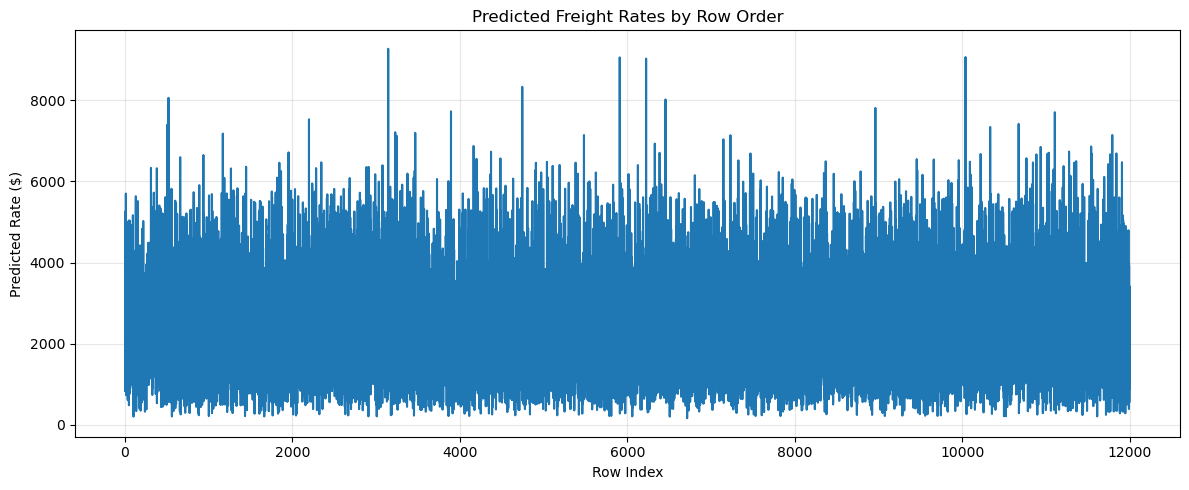

In [38]:
plt.figure(figsize=(12, 5))
plt.plot(df["predicted_rate"].reset_index(drop=True))
plt.title("Predicted Freight Rates by Row Order")
plt.xlabel("Row Index")
plt.ylabel("Predicted Rate ($)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Rate groups
df["rate_category"] = pd.cut(
    df["predicted_rate"],
    bins=[-np.inf, 1000, 2000, 3000, 4000, np.inf],
    labels=["Below $1,000", "$1,000–$2,000",
            "$2,000–$3,000", "$3,000–$4,000", "Above $4,000"]
)

In [39]:
display(df["rate_category"].value_counts().sort_index())

rate_category
Below $1,000     1854
$1,000–$2,000    3924
$2,000–$3,000    2515
$3,000–$4,000    1810
Above $4,000     1897
Name: count, dtype: int64

In [40]:
# Check final dataset
print("Final shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

# Confirm required columns
required_columns = ["load_id", "predicted_rate"]

assert all(col in df.columns for col in required_columns), \
    "Required columns are missing!"

assert df["load_id"].notna().all(), "Missing load IDs!"
assert df["predicted_rate"].notna().all(), "Missing predictions!"

# Preserve the required submission format
submission = df[required_columns].copy()

# Export cleaned predictions
submission.to_csv("validation_predictions_cleaned.csv", index=False)

print("Saved: validation_predictions_cleaned.csv")
display(submission.head())

Final shape: (12000, 3)
Missing values:
 load_id           0
predicted_rate    0
rate_category     0
dtype: int64
Duplicate rows: 0
Saved: validation_predictions_cleaned.csv


,load_id,predicted_rate
0,TE-000001,828.38
1,TE-000002,5054.89
2,TE-000003,5167.78
3,TE-000004,4140.13
4,TE-000005,1836.93


## 3. Train and Test

In [41]:
train =pd.read_csv("train-test.csv")

In [42]:
train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [43]:
train.shape

(48000, 14)

In [44]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [45]:
print("Dataset loaded successfully")
print("Shape:", train.shape)
print("Rows:", train.shape[0])
print("Columns:", train.shape[1])

Dataset loaded successfully
Shape: (48000, 14)
Rows: 48000
Columns: 14


In [46]:
print("Columns:")
print(train.columns.tolist())

Columns:
['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']


In [47]:
train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [48]:
display(train.describe().T)


,count,mean,std,min,25%,50%,75%,max
pickup_lat,48000.0,35.647545,4.315285,28.35765,31.98691,35.29479,39.411040,44.30296
pickup_lon,48000.0,-90.928964,13.482431,-121.69849,-98.40059,-88.08915,-83.285060,-69.50000
delivery_lat,48000.0,35.641175,4.317199,28.35765,31.98691,35.29479,39.411040,44.30296
delivery_lon,48000.0,-90.857310,13.476589,-121.69849,-98.40059,-87.52871,-83.285060,-69.50000
distance,48000.0,1135.856654,728.564416,70.00000,550.40000,953.30000,1645.525000,3439.80000
weight,47700.0,31028.844004,9391.440620,-47500.00000,25800.00000,31436.50000,37018.000000,47500.00000
market_index,47626.0,1.083387,0.168091,0.67639,0.94967,1.05580,1.219590,1.46778
quote_signal,48000.0,2.062468,0.291391,0.69228,1.89103,2.05575,2.221685,3.61035
posted_rate,48000.0,2373.980682,1486.493245,57.22000,1251.55500,2030.76000,3330.750000,25533.00000


In [49]:
display(train.describe(include="object").T)


,count,unique,top,freq
load_id,48000,48000,TR-000001,1
pickup,48000,64,Oklahoma City,1242
delivery,48000,64,Lexington,1197
equipment,48000,3,Dry Van,27202
date,48000,304,2025-06-17,198


In [50]:
# Missing values
missing = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": train.isnull().mean() * 100
}).sort_values("Missing Percentage", ascending=False)

display(missing)

,Missing Count,Missing Percentage
market_index,374,0.779167
weight,300,0.625000
load_id,0,0.000000
pickup,0,0.000000
delivery,0,0.000000
pickup_lat,0,0.000000
pickup_lon,0,0.000000
delivery_lat,0,0.000000
delivery_lon,0,0.000000
distance,0,0.000000


In [51]:
print("Duplicate rows:", train.duplicated().sum())


Duplicate rows: 0


In [52]:
# Unique values per column
print("\nUnique values:")
display(train.nunique().to_frame("Unique Values"))


Unique values:


,Unique Values
load_id,48000
pickup,64
delivery,64
pickup_lat,64
pickup_lon,63
delivery_lat,64
delivery_lon,63
distance,21204
equipment,3
weight,23678


In [53]:
train["date"] = pd.to_datetime(train["date"], errors="coerce")


In [54]:
# Check invalid numeric values
numeric_cols = [
    "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon",
    "distance", "weight", "market_index", "quote_signal", "posted_rate"
]

for col in numeric_cols:
    train[col] = pd.to_numeric(train[col], errors="coerce")

print("Date range:", train["date"].min(), "to", train["date"].max())


Date range: 2025-01-01 00:00:00 to 2025-10-31 00:00:00


In [55]:
numeric_cols

['pickup_lat',
 'pickup_lon',
 'delivery_lat',
 'delivery_lon',
 'distance',
 'weight',
 'market_index',
 'quote_signal',
 'posted_rate']

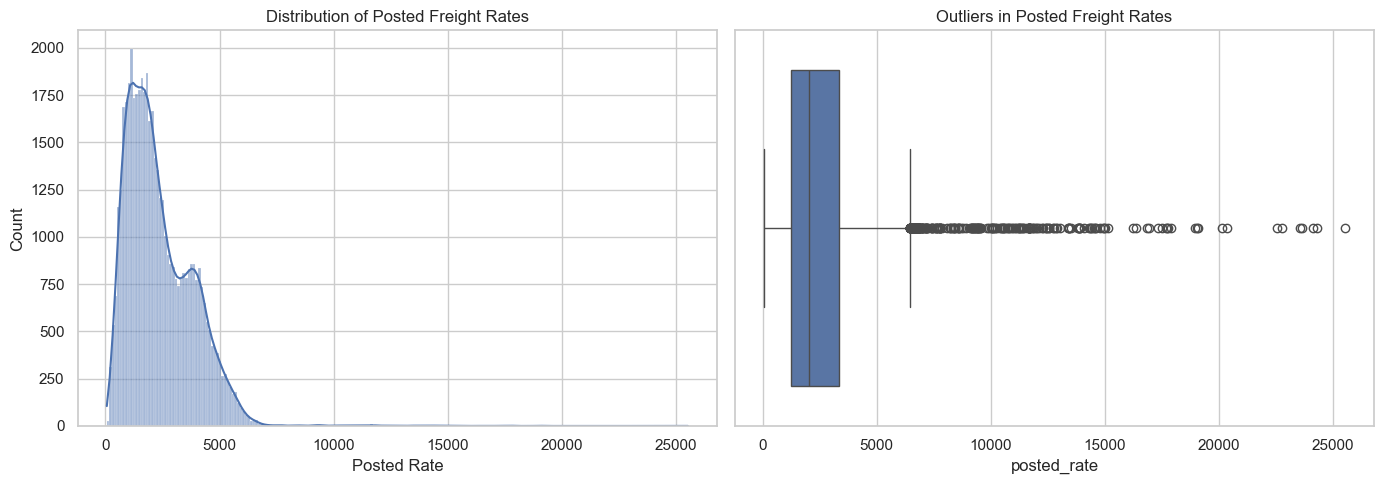

In [56]:

# Distribution of the target variable
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train["posted_rate"].dropna(), kde=True, ax=axes[0])
axes[0].set_title("Distribution of Posted Freight Rates")
axes[0].set_xlabel("Posted Rate")

sns.boxplot(x=train["posted_rate"], ax=axes[1])
axes[1].set_title("Outliers in Posted Freight Rates")

plt.tight_layout()
plt.show()


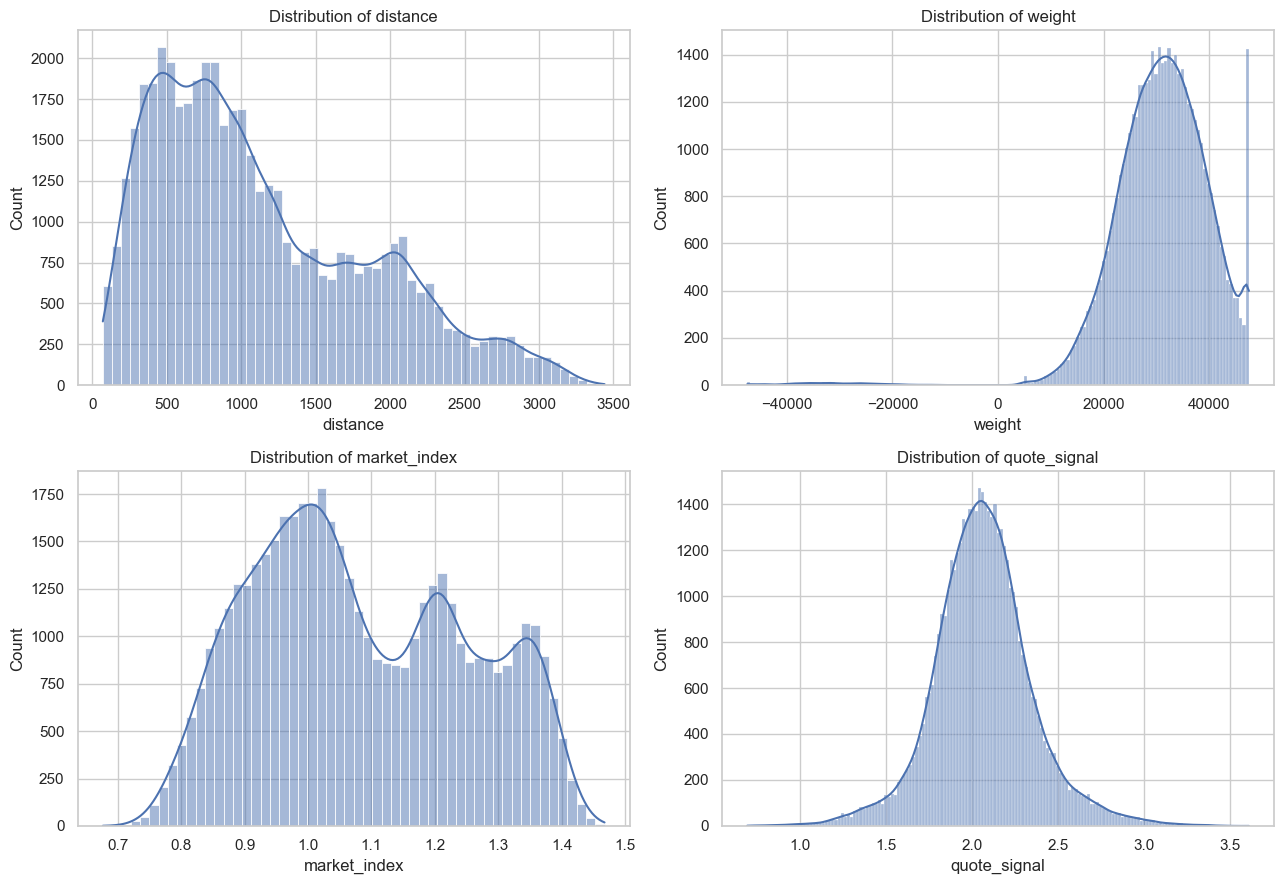

In [57]:

# Distributions of numerical features
features = ["distance", "weight", "market_index", "quote_signal"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for col, ax in zip(features, axes.flatten()):
    sns.histplot(data=train, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")

plt.tight_layout()
plt.show()


In [58]:

categorical_cols = ["pickup", "delivery", "equipment"]

for col in categorical_cols:
    print(f"\nTop 10 values in {col}:")
    display(train[col].value_counts().head(10).to_frame("Shipment Count"))



Top 10 values in pickup:


,Shipment Count
pickup,
Oklahoma City,1242
Lexington,1209
Bakersfield,1193
Fort Wayne,1170
Hartford,1150
Richmond,1140
Nashville,1124
Phoenix,1121
Baton Rouge,1115



Top 10 values in delivery:


,Shipment Count
delivery,
Lexington,1197
Fort Wayne,1176
Baton Rouge,1167
Bakersfield,1156
Hartford,1143
Oklahoma City,1140
Richmond,1109
Atlanta,1096
Phoenix,1090



Top 10 values in equipment:


,Shipment Count
equipment,
Dry Van,27202
Reefer,12045
Flatbed,8753


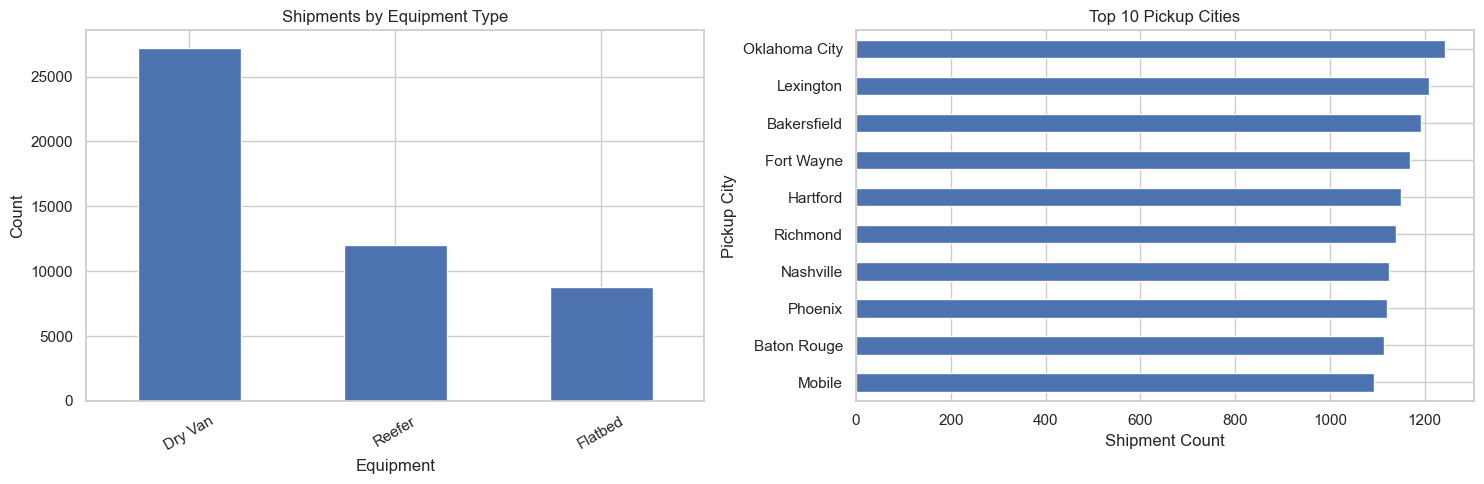

In [59]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

train["equipment"].value_counts().plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Shipments by Equipment Type")
axes[0].set_xlabel("Equipment")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=30)

train["pickup"].value_counts().head(10).sort_values().plot(
    kind="barh", ax=axes[1]
)
axes[1].set_title("Top 10 Pickup Cities")
axes[1].set_xlabel("Shipment Count")
axes[1].set_ylabel("Pickup City")

plt.tight_layout()
plt.show()


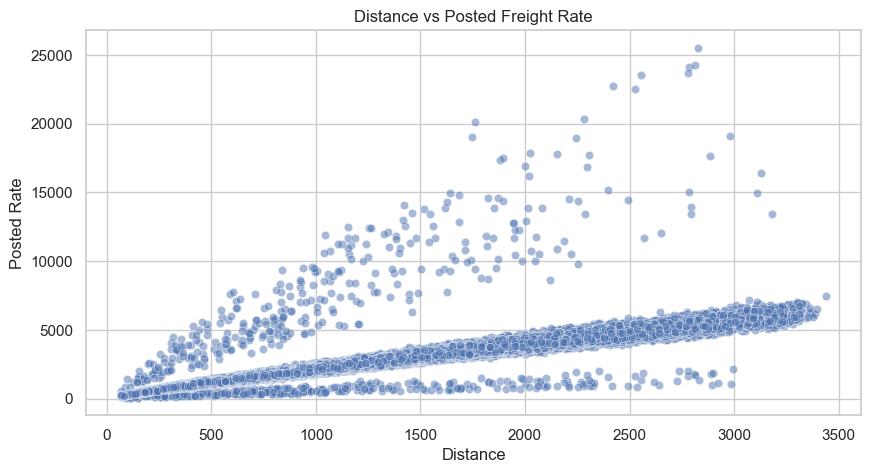

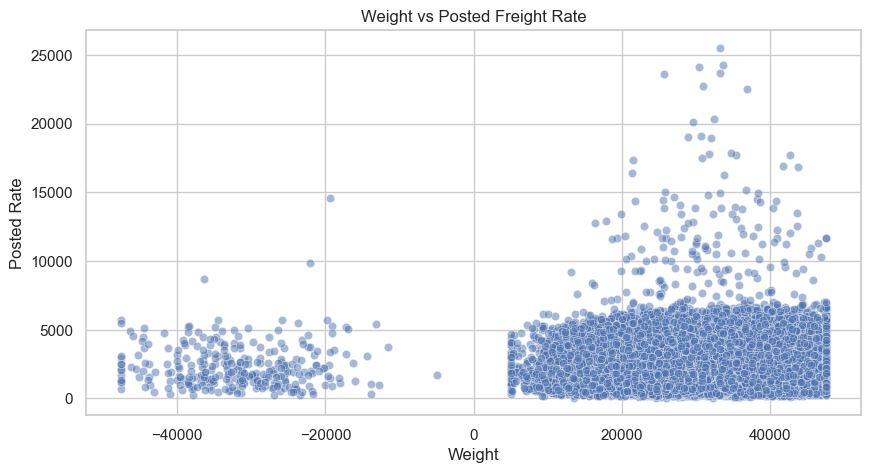

In [60]:

# Distance versus posted rate
sns.scatterplot(
    data=train,
    x="distance",
    y="posted_rate",
    alpha=0.5
)
plt.title("Distance vs Posted Freight Rate")
plt.xlabel("Distance")
plt.ylabel("Posted Rate")
plt.show()

# Weight versus posted rate
sns.scatterplot(
    data=train,
    x="weight",
    y="posted_rate",
    alpha=0.5
)
plt.title("Weight vs Posted Freight Rate")
plt.xlabel("Weight")
plt.ylabel("Posted Rate")
plt.show()


,count,mean,median,std
equipment,,,,
Reefer,12045,2553.636939,2196.670,1589.670824
Flatbed,8753,2445.087223,2076.810,1505.053087
Dry Van,27202,2271.548686,1953.035,1423.029914


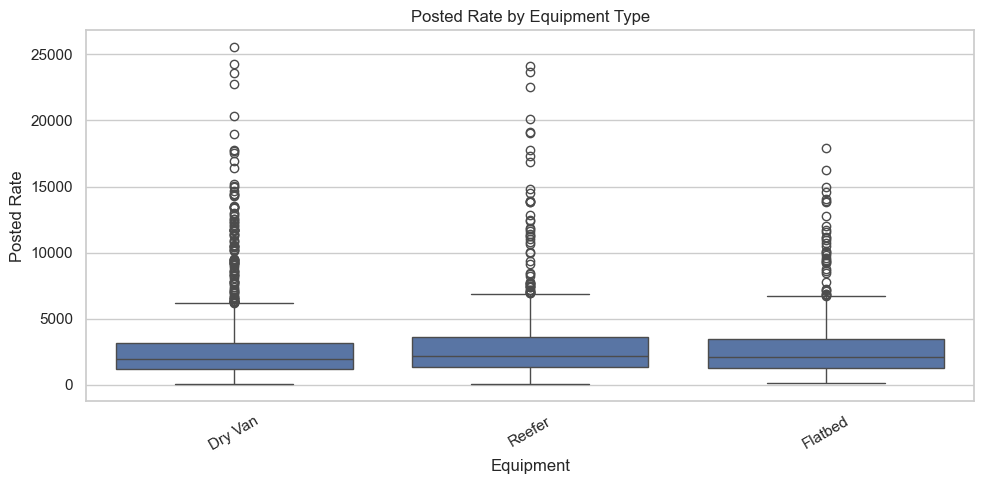

In [61]:

equipment_rates = (
    train.groupby("equipment")["posted_rate"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
)

display(equipment_rates)

sns.boxplot(
    data=train,
    x="equipment",
    y="posted_rate"
)
plt.title("Posted Rate by Equipment Type")
plt.xlabel("Equipment")
plt.ylabel("Posted Rate")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


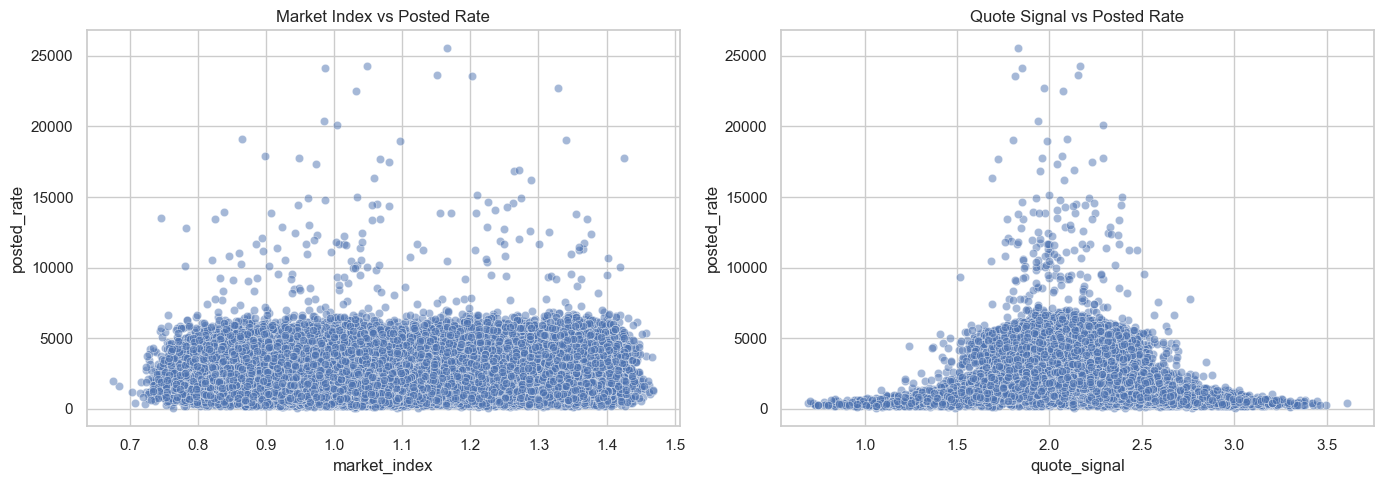

In [62]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=train, x="market_index", y="posted_rate",
    alpha=0.5, ax=axes[0]
)
axes[0].set_title("Market Index vs Posted Rate")

sns.scatterplot(
    data=train, x="quote_signal", y="posted_rate",
    alpha=0.5, ax=axes[1]
)
axes[1].set_title("Quote Signal vs Posted Rate")

plt.tight_layout()
plt.show()


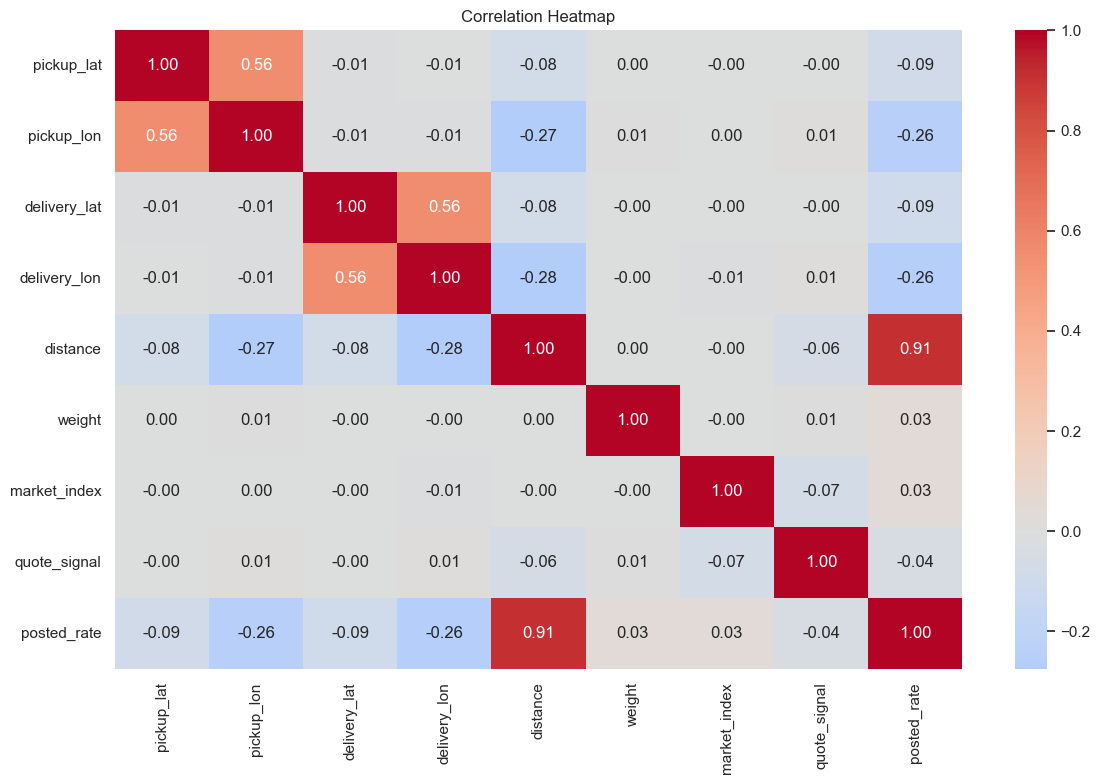

,Correlation with posted_rate
distance,0.908519
delivery_lon,-0.257086
pickup_lon,-0.255058
delivery_lat,-0.091970
pickup_lat,-0.090873
quote_signal,-0.039858
weight,0.034840
market_index,0.034165


In [63]:

numeric_data = train.select_dtypes(include=np.number)

correlation = numeric_data.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Features most correlated with posted_rate
if "posted_rate" in correlation.columns:
    display(
        correlation["posted_rate"]
        .drop("posted_rate")
        .sort_values(key=abs, ascending=False)
        .to_frame("Correlation with posted_rate")
    )


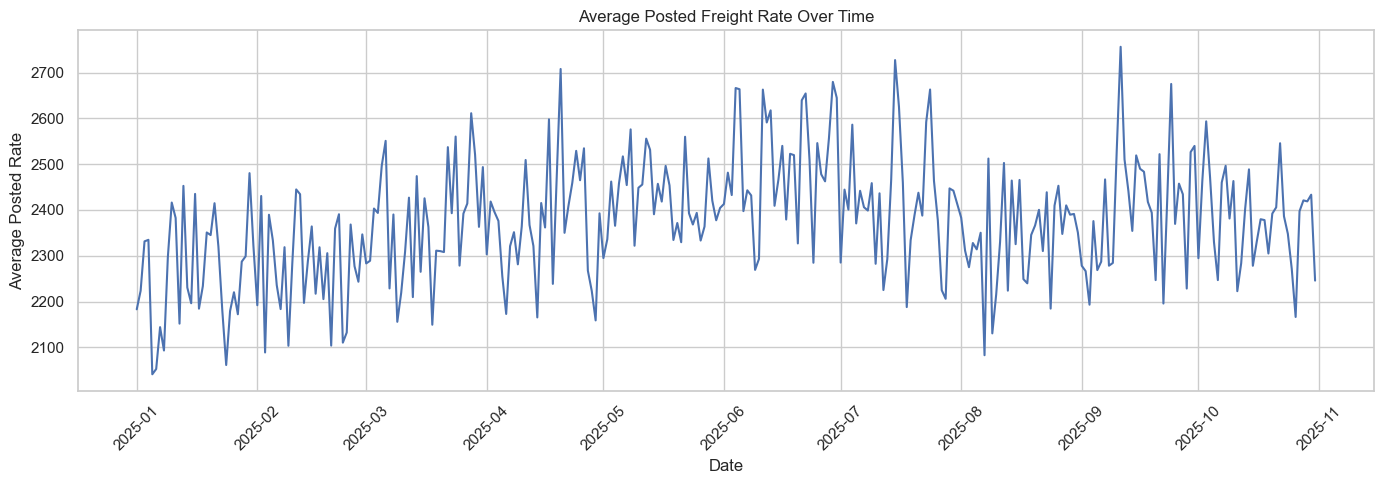

In [64]:

daily_rates = (
    train.dropna(subset=["date", "posted_rate"])
    .groupby("date")["posted_rate"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

plt.figure(figsize=(14, 5))
sns.lineplot(data=daily_rates, x="date", y="mean")
plt.title("Average Posted Freight Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Average Posted Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [65]:
display(daily_rates.head())


,date,mean,median,count
0,2025-01-01,2182.959586,1991.870,145
1,2025-01-02,2223.485595,1885.395,168
2,2025-01-03,2331.391154,1892.985,156
3,2025-01-04,2334.728782,1967.150,156
4,2025-01-05,2041.046688,1626.405,154


In [66]:

for col in ["distance", "weight", "market_index", "quote_signal", "posted_rate"]:
    values = train[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = ((values < lower) | (values > upper)).sum()

    print(f"\n{col}")
    print(f"Lower bound: {lower:.3f}")
    print(f"Upper bound: {upper:.3f}")
    print(f"Potential outliers: {outliers} ({outliers / len(values) * 100:.2f}%)")



distance
Lower bound: -1092.287
Upper bound: 3288.213
Potential outliers: 32 (0.07%)

weight
Lower bound: 8973.000
Upper bound: 53845.000
Potential outliers: 424 (0.89%)

market_index
Lower bound: 0.545
Upper bound: 1.624
Potential outliers: 0 (0.00%)

quote_signal
Lower bound: 1.395
Upper bound: 2.718
Potential outliers: 1956 (4.08%)

posted_rate
Lower bound: -1867.238
Upper bound: 6449.543
Potential outliers: 260 (0.54%)


In [67]:

print("=" * 45)
print("EXPLORATORY DATA ANALYSIS SUMMARY")
print("=" * 45)

print("Total rows:", len(train))
print("Total columns:", len(train.columns))
print("Duplicate rows:", train.duplicated().sum())
print("Total missing cells:", train.isnull().sum().sum())
print("Unique shipment IDs:", train["load_id"].nunique())

print("\nTarget variable: posted_rate")
print("Mean rate:", round(train["posted_rate"].mean(), 2))
print("Median rate:", round(train["posted_rate"].median(), 2))
print("Minimum rate:", round(train["posted_rate"].min(), 2))
print("Maximum rate:", round(train["posted_rate"].max(), 2))
print("Standard deviation:", round(train["posted_rate"].std(), 2))

print("\nEquipment types:")
print(train["equipment"].value_counts(dropna=False))

print("\nDate range:")
print(train["date"].min(), "to", train["date"].max())

print("\nEDA completed.")


EXPLORATORY DATA ANALYSIS SUMMARY
Total rows: 48000
Total columns: 14
Duplicate rows: 0
Total missing cells: 674
Unique shipment IDs: 48000

Target variable: posted_rate
Mean rate: 2373.98
Median rate: 2030.76
Minimum rate: 57.22
Maximum rate: 25533.0
Standard deviation: 1486.49

Equipment types:
equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

Date range:
2025-01-01 00:00:00 to 2025-10-31 00:00:00

EDA completed.
